In [25]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [26]:
df = pd.read_csv("titanic_dataset.csv")

In [27]:
df.shape

(891, 15)

In [28]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [29]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [30]:
num_cols = ["age", "fare", "sibsp", "parch"]
cat_cols = ["survived", "pclass", "sex", "embarked", "calss", "who", "adult_male", "deck", "embark_town", "alone"]

print("\nNumerical columns:", num_cols)
print("\nCategorical columns:", cat_cols)


Numerical columns: ['age', 'fare', 'sibsp', 'parch']

Categorical columns: ['survived', 'pclass', 'sex', 'embarked', 'calss', 'who', 'adult_male', 'deck', 'embark_town', 'alone']


In [31]:
df_num = df[num_cols].dropna()

In [32]:
df_num.head()

,age,fare,sibsp,parch
0,22.0,7.2500,1,0
1,38.0,71.2833,1,0
2,26.0,7.9250,0,0
3,35.0,53.1000,1,0
4,35.0,8.0500,0,0


In [33]:
df["survived_label"] = df["survived"].map({0: "NO", 1:"Yes"})

In [34]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,survived_label
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,NO
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Yes
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Yes
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Yes
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,NO


### Numerical vs Numerical

Scatter Plot

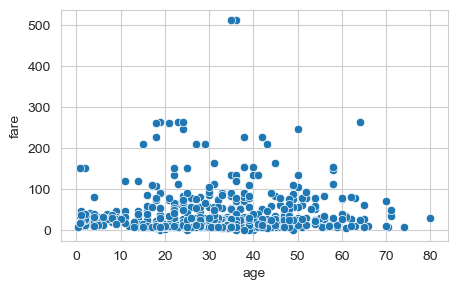

In [35]:
plt.figure(figsize=(5,3))
sns.scatterplot(x=df["age"], y=df["fare"])
plt.xlabel("age")
plt.ylabel("fare")
plt.show()

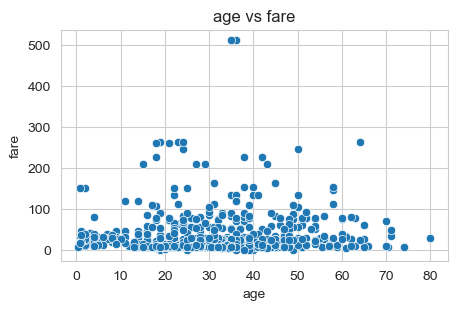

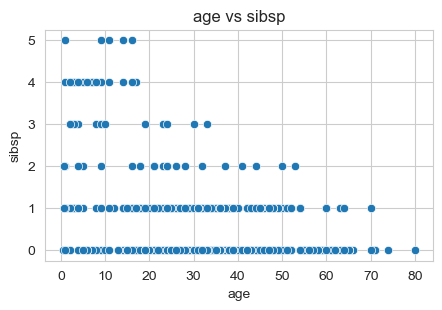

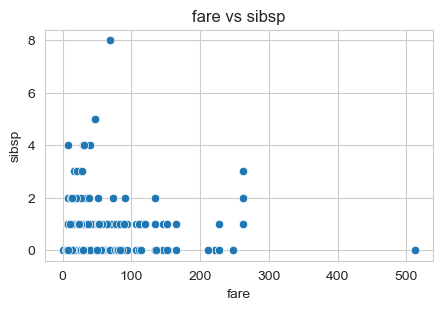

In [36]:
num_pairs = [
    {"age", "fare"},
    {"age", "sibsp"},
    {"fare", "sibsp"}
]
for x, y in num_pairs:
    plt.figure(figsize=(5,3))
    sns.scatterplot(x=df[x], y=df[y])
    plt.title(f"{x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

Correlation Matrix

In [37]:
print("Correlation Matrix")
df_num.corr()

# -1 -> high negative correlation; +1 -> high positive correlations

Correlation Matrix


,age,fare,sibsp,parch
age,1.000000,0.096067,-0.308247,-0.189119
fare,0.096067,1.000000,0.138329,0.205119
sibsp,-0.308247,0.138329,1.000000,0.383820
parch,-0.189119,0.205119,0.383820,1.000000


In [38]:
print("Pearson Correlation with fare:")
for col in num_cols:
    r, p = pearsonr(df_num[col], df_num["fare"])
    print(f"{col} vs fare: r={r:.3f}; p={p:.3f}")

Pearson Correlation with fare:
age vs fare: r=0.096; p=0.010
fare vs fare: r=1.000; p=0.000
sibsp vs fare: r=0.138; p=0.000
parch vs fare: r=0.205; p=0.000


### Numerical vs Categorical


Boxplots

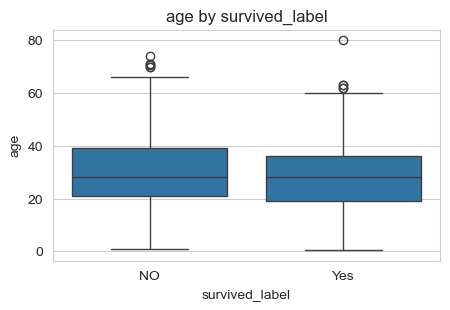

In [39]:
plt.figure(figsize=(5,3))
sns.boxplot(x=df["survived_label"], y=df["age"])
plt.xlabel("survived_label")
plt.ylabel("age")
plt.title("age by survived_label")
plt.show()

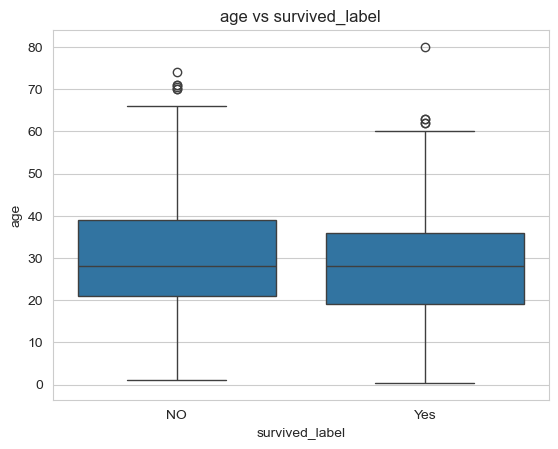

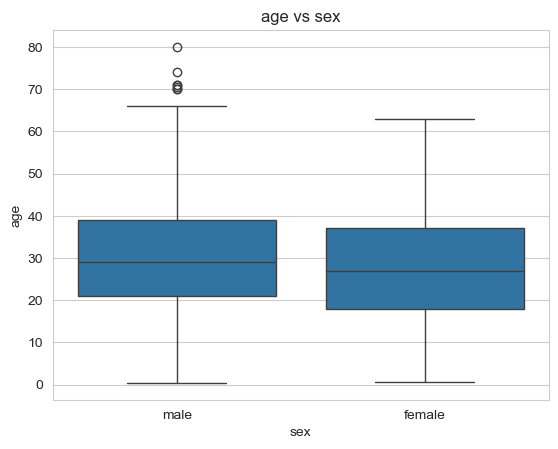

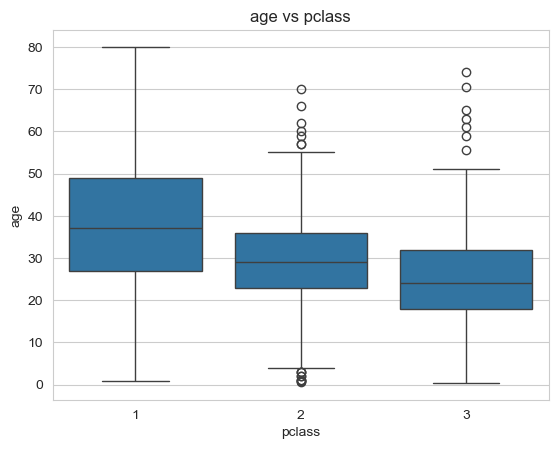

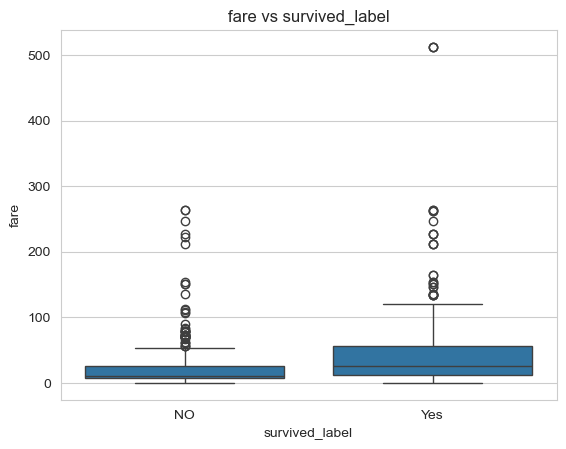

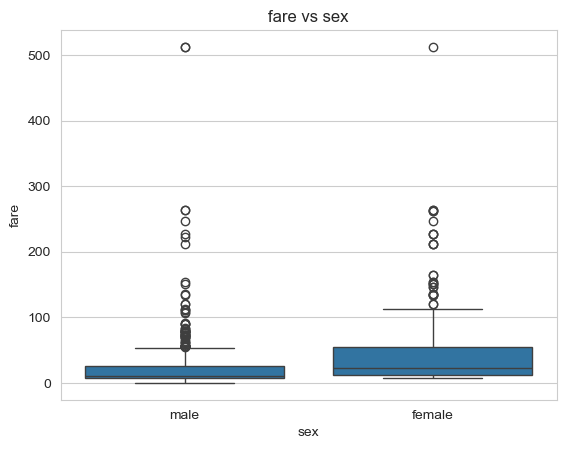

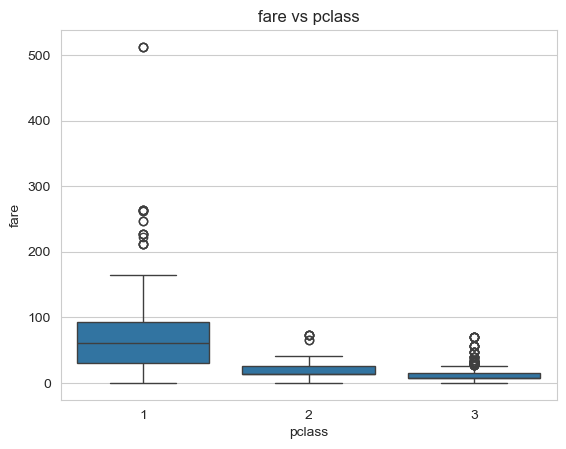

In [40]:
num_for_box = ["age", "fare"]
cat_for_box = ["survived_label", "sex", "pclass"]

for num in num_for_box:
    for cat in cat_for_box:
        plt.Figure(figsize=(5,3))
        sns.boxplot(x=df[cat], y=df[num])
        plt.title(f"{num} vs {cat}")
        plt.xlabel(cat)
        plt.ylabel(num)
        plt.show()

**Grouped Statistics**

In [41]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,survived_label
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,NO
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Yes
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Yes
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Yes
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,NO


In [51]:
df_num.columns

Index(['age', 'fare', 'sibsp', 'parch'], dtype='object')

In [52]:
df[num_cols + ["survived_label"]]

,age,fare,sibsp,parch,survived_label
0,22.0,7.2500,1,0,NO
1,38.0,71.2833,1,0,Yes
2,26.0,7.9250,0,0,Yes
3,35.0,53.1000,1,0,Yes
4,35.0,8.0500,0,0,NO
...,...,...,...,...,...
886,27.0,13.0000,0,0,NO
887,19.0,30.0000,0,0,Yes
888,NaN,23.4500,1,2,NO
889,26.0,30.0000,0,0,Yes


In [55]:
df[num_cols + ["survived_label"]].groupby("survived_label").mean()

,age,fare,sibsp,parch
survived_label,,,,
NO,30.626179,22.117887,0.553734,0.329690
Yes,28.343690,48.395408,0.473684,0.464912


In [58]:
for cat in ["survived_label", "sex", "pclass"]:
    print(f"Grouped statistics for fare by {cat}")
    print(df.groupby(cat)["fare"].mean())
    print("-"*50)

Grouped statistics for fare by survived_label
survived_label
NO     22.117887
Yes    48.395408
Name: fare, dtype: float64
--------------------------------------------------
Grouped statistics for fare by sex
sex
female    44.479818
male      25.523893
Name: fare, dtype: float64
--------------------------------------------------
Grouped statistics for fare by pclass
pclass
1    84.154687
2    20.662183
3    13.675550
Name: fare, dtype: float64
--------------------------------------------------


### Categorical vs Categorical Features

In [60]:
print("Crosstab: sex vs survives")
print(pd.crosstab(df["sex"],df["survived_label"]))

print("Crosstab: sex vs survived")
print(pd.crosstab(df["pclass"], df["survived_label"]))

Crosstab: sex vs survives
survived_label   NO  Yes
sex                     
female           81  233
male            468  109
Crosstab: sex vs survived
survived_label   NO  Yes
pclass                  
1                80  136
2                97   87
3               372  119


Countplot

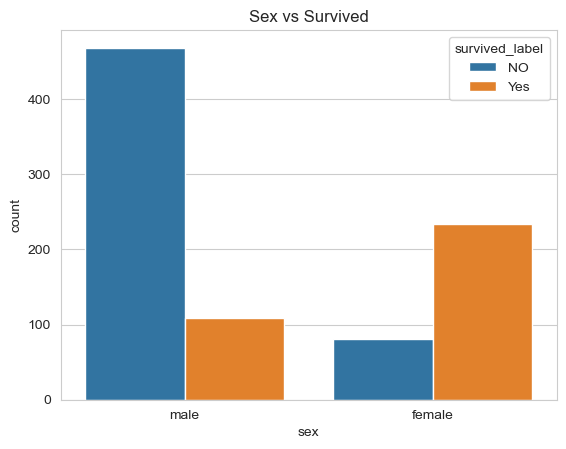

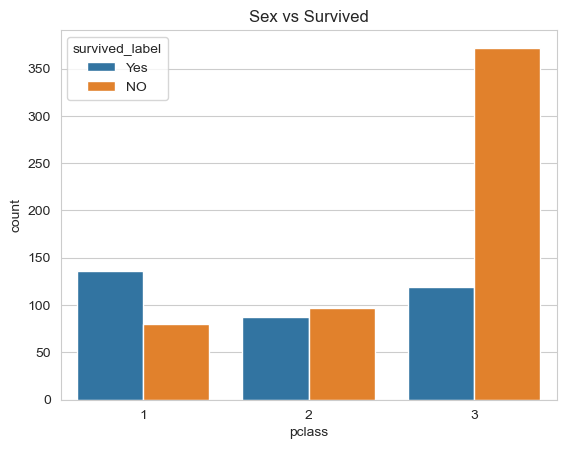

In [65]:
plt.Figure(figsize=(5,3))
sns.countplot(x=df["sex"], hue=df["survived_label"])
plt.title("Sex vs Survived")
plt.show()

plt.Figure(figsize=(5,3))
sns.countplot(x=df["pclass"], hue=df["survived_label"])
plt.title("Sex vs Survived")
plt.show()